In [1]:
import json
import time

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

train = pd.read_csv("../data/processed/train.csv", parse_dates=["StartDatetime", "EndDatetime"])
test = pd.read_csv("../data/processed/test.csv", parse_dates=["StartDatetime", "EndDatetime"])

with open("../models/feature_columns.json") as file:
    FEATURES = json.load(file)["features"]

X_train, y_train = train[FEATURES], train["Demand"]
X_test, y_test = test[FEATURES], test["Demand"]
print(X_train.shape, X_test.shape)     

(58260, 32) (14566, 32)


In [3]:
def evaluate(model, name):
    """Score a fitted model on the test set (and on train, to check overfitting)."""
    test_pred = model.predict(X_test)
    train_pred = model.predict(X_train)
    mse = mean_squared_error(y_test, test_pred)
    return {
        "Model": name,
        "MAE": mean_absolute_error(y_test, test_pred),
        "MSE": mse,
        "RMSE": np.sqrt(mse),
        "R2": r2_score(y_test, test_pred),
        "Train_R2": r2_score(y_train, train_pred),
    }

models = {
    "Baseline (mean)": DummyRegressor(strategy="mean"),
    "Linear Regression": make_pipeline(StandardScaler(), LinearRegression()),
    "Decision Tree": DecisionTreeRegressor(max_depth=8, min_samples_leaf=50, random_state=42),
    "Random Forest": RandomForestRegressor(
        n_estimators=200, max_depth=12, min_samples_leaf=20, n_jobs=-1, random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=200, max_depth=4, learning_rate=0.05, random_state=42),
    "XGBoost": XGBRegressor(
        n_estimators=300, learning_rate=0.05, max_depth=5,
        subsample=0.8, colsample_bytree=0.8, random_state=42, n_jobs=-1),
    "LightGBM": LGBMRegressor(
        n_estimators=300, learning_rate=0.05, num_leaves=31,
        random_state=42, verbose=-1),
}

In [4]:
rows = []
fitted = {}

for name, model in models.items():
    start = time.time()
    model.fit(X_train, y_train)
    fitted[name] = model
    result = evaluate(model, name)
    rows.append(result)
    print(f"{name:20s} R2={result['R2']:.3f}  MAE={result['MAE']:.2f}  ({time.time() - start:.0f}s)")

results = pd.DataFrame(rows).set_index("Model").sort_values("RMSE")
results["Overfit_Gap"] = results["Train_R2"] - results["R2"]
results.round(3)

Baseline (mean)      R2=-0.001  MAE=10.87  (0s)
Linear Regression    R2=0.314  MAE=8.57  (0s)
Decision Tree        R2=0.318  MAE=8.42  (0s)
Random Forest        R2=0.347  MAE=8.20  (17s)
Gradient Boosting    R2=0.328  MAE=8.46  (55s)
XGBoost              R2=0.319  MAE=8.56  (2s)
LightGBM             R2=0.351  MAE=8.16  (2s)


,MAE,MSE,RMSE,R2,Train_R2,Overfit_Gap
Model,,,,,,
LightGBM,8.159,125.706,11.212,0.351,0.451,0.100
Random Forest,8.198,126.478,11.246,0.347,0.455,0.109
Gradient Boosting,8.465,130.140,11.408,0.328,0.395,0.067
XGBoost,8.559,131.775,11.479,0.319,0.434,0.115
Decision Tree,8.419,132.029,11.490,0.318,0.375,0.057
Linear Regression,8.568,132.817,11.525,0.314,0.333,0.019
Baseline (mean),10.865,193.717,13.918,-0.001,0.000,0.001


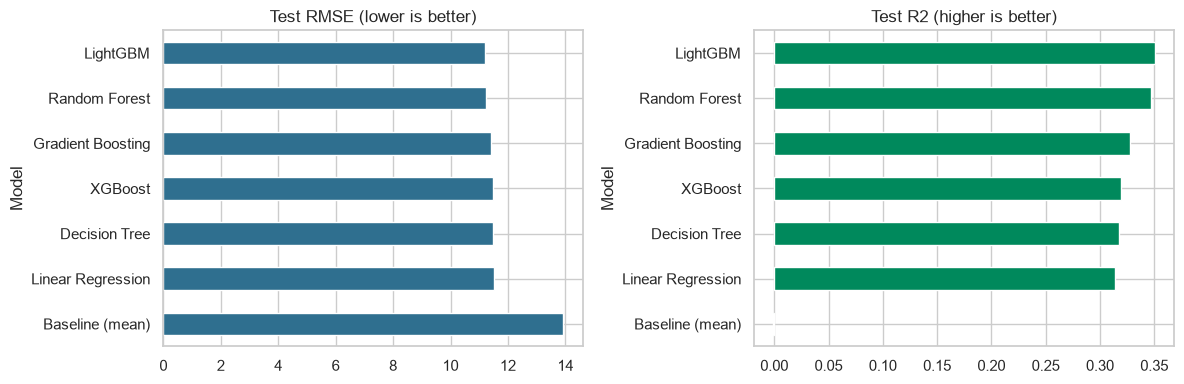

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

results["RMSE"].sort_values(ascending=False).plot(kind="barh", ax=axes[0], color="#2F6F8F")
axes[0].set_title("Test RMSE (lower is better)")

results["R2"].sort_values().plot(kind="barh", ax=axes[1], color="#00895C")
axes[1].set_title("Test R2 (higher is better)")

plt.tight_layout()
plt.savefig("../docs/figures/10_regression_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

In [6]:
baseline = results.loc["Baseline (mean)"]
best_name = results.index[0]
best = results.loc[best_name]

print("Best model:", best_name)
print(f"MAE improved by {100 * (baseline['MAE'] - best['MAE']) / baseline['MAE']:.0f}%")
print(f"RMSE improved by {100 * (baseline['RMSE'] - best['RMSE']) / baseline['RMSE']:.0f}%")

Best model: LightGBM
MAE improved by 25%
RMSE improved by 19%


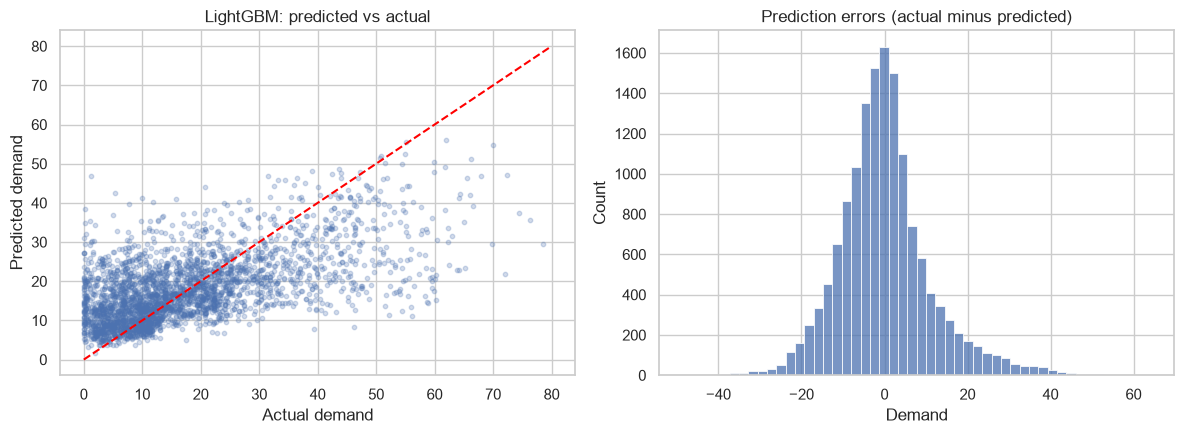

In [7]:
best_model = fitted[best_name]
predictions = best_model.predict(X_test)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

sample = np.random.RandomState(42).choice(len(y_test), 3000, replace=False)
axes[0].scatter(y_test.iloc[sample], predictions[sample], alpha=0.25, s=10)
axes[0].plot([0, 80], [0, 80], color="red", linestyle="--")      # perfect predictions lie on this line
axes[0].set_xlabel("Actual demand")
axes[0].set_ylabel("Predicted demand")
axes[0].set_title(f"{best_name}: predicted vs actual")

sns.histplot(y_test - predictions, bins=50, ax=axes[1])
axes[1].set_title("Prediction errors (actual minus predicted)")

plt.tight_layout()
plt.savefig("../docs/figures/11_predicted_vs_actual.png", dpi=150, bbox_inches="tight")
plt.show()

In [8]:
check = pd.DataFrame({"actual": y_test.values, "predicted": predictions})
check["actual_group"] = pd.qcut(check["actual"], 4, labels=["Lowest 25%", "Low-mid", "High-mid", "Highest 25%"])
print(check.groupby("actual_group", observed=True)[["actual", "predicted"]].mean().round(1))

              actual  predicted
actual_group                   
Lowest 25%       3.8       13.1
Low-mid         10.6       14.0
High-mid        19.0       18.4
Highest 25%     37.7       25.4


In [9]:
leaky_features = FEATURES + ["DurationCalc"]

leaky_model = LGBMRegressor(
    n_estimators=300, learning_rate=0.05, num_leaves=31, random_state=42, verbose=-1)
leaky_model.fit(train[leaky_features], y_train)
leaky_pred = leaky_model.predict(test[leaky_features])

print(f"Without Duration: R2 = {r2_score(y_test, predictions):.3f}   MAE = {mean_absolute_error(y_test, predictions):.2f}")
print(f"With Duration:    R2 = {r2_score(y_test, leaky_pred):.3f}   MAE = {mean_absolute_error(y_test, leaky_pred):.2f}")

Without Duration: R2 = 0.351   MAE = 8.16
With Duration:    R2 = 0.792   MAE = 3.25


In [10]:
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit

search = RandomizedSearchCV(
    LGBMRegressor(random_state=42, verbose=-1),
    param_distributions={
        "n_estimators": [200, 300, 500],
        "learning_rate": [0.02, 0.05, 0.1],
        "num_leaves": [15, 31, 63],
        "min_child_samples": [20, 50, 100],
    },
    n_iter=12,
    cv=TimeSeriesSplit(n_splits=3),            # respects time order, no peeking at the future
    scoring="neg_root_mean_squared_error",
    random_state=42,
    n_jobs=-1,
)
search.fit(X_train, y_train)

print("Best settings:", search.best_params_)
tuned_result = evaluate(search.best_estimator_, "LightGBM (tuned)")
print({k: round(v, 3) for k, v in tuned_result.items() if k != "Model"})

Best settings: {'num_leaves': 31, 'n_estimators': 300, 'min_child_samples': 100, 'learning_rate': 0.02}
{'MAE': 8.176, 'MSE': 125.596, 'RMSE': np.float64(11.207), 'R2': 0.351, 'Train_R2': 0.41}


In [11]:
results.round(4).to_csv("../models/regression_results.csv")
joblib.dump(fitted[best_name], "../models/best_regressor.pkl")
print("Saved results and", best_name)

Saved results and LightGBM
